# Практическая работа 1. Одномерная сетка и уравнения Фредгольма

In [131]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import integrate
from math import sin, pi

## Этап A. Построение сетки и квадратурных весов

In [132]:
a = -1
b = 1
n = 200
k = 8

omega_space = np.linspace(a, b, num=n)

In [133]:
def make_grid(
    a: float,
    b: float,
    n: int
):
    x = np.linspace(a, b, n)
    h = x[1] - x[0]

    w = np.full(n, h)
    w[0] = w[-1] = h / 2

    return x, w, h 

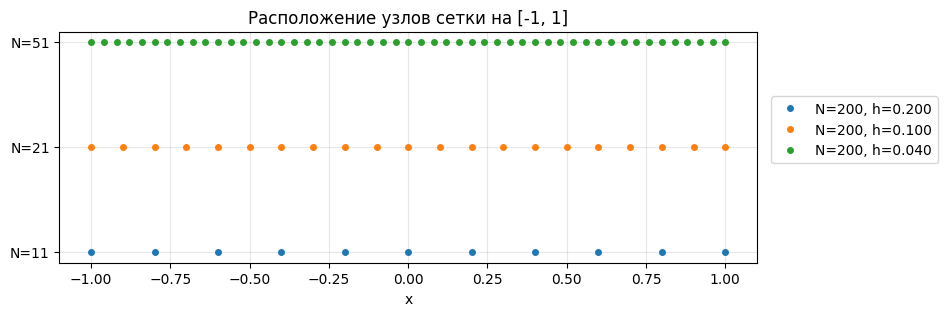

In [134]:
plt.figure(figsize=(9, 3))

for index, value in enumerate([11, 21, 51]):
    x, w, h = make_grid(a, b, value)
    plt.plot(x, np.full_like(x, index), 'o', ms=4, label=f'N={n}, h={h:.3f}')

plt.yticks([0, 1, 2], ['N=11', 'N=21', 'N=51'])
plt.xlabel('x')
plt.title('Расположение узлов сетки на [-1, 1]')
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.01, 0.75))
plt.show()

In [135]:
functions = [
    lambda x: 1,
    lambda x: x**2,
    lambda x: np.sin(np.pi * x)
]

x, w, h = make_grid(a, b, n)

for i in functions:

    scipy_value, scipy_error = integrate.quad(i, a, b)

    grid_value = np.sum(w * i(x))

    print(f'''\tscipy.integrate value = {scipy_value:.2f}
    \tscipy.error - {scipy_error:.2f}
    \tgrid value - {grid_value:.2f}\n''')

	scipy.integrate value = 2.00
    	scipy.error - 0.00
    	grid value - 2.00

	scipy.integrate value = 0.67
    	scipy.error - 0.00
    	grid value - 0.67

	scipy.integrate value = 0.00
    	scipy.error - 0.00
    	grid value - 0.00



## Этап B. Акустическое уравнение Фредгольма в одномерной среде

In [136]:
f_g = lambda dist, k: (1j / (2 * k)) * np.exp(1j * k * dist)
f_u0 = lambda x, k: np.exp(1j * k * x) 

In [137]:
eta = np.zeros_like(x, dtype=np.complex128)
mask = (x >= -0.3) & (x <= 0.3)
eta[mask] = 0.3 - 0.05j

In [138]:
X, Y = np.meshgrid(x, x, indexing='ij')
dist = np.abs(X - Y)

In [139]:
g = f_g(dist, k)
u0 = f_u0(x, k)

In [140]:
A = np.eye(n) + k**2 * w * eta * g

In [141]:
u = np.linalg.solve(A, u0)

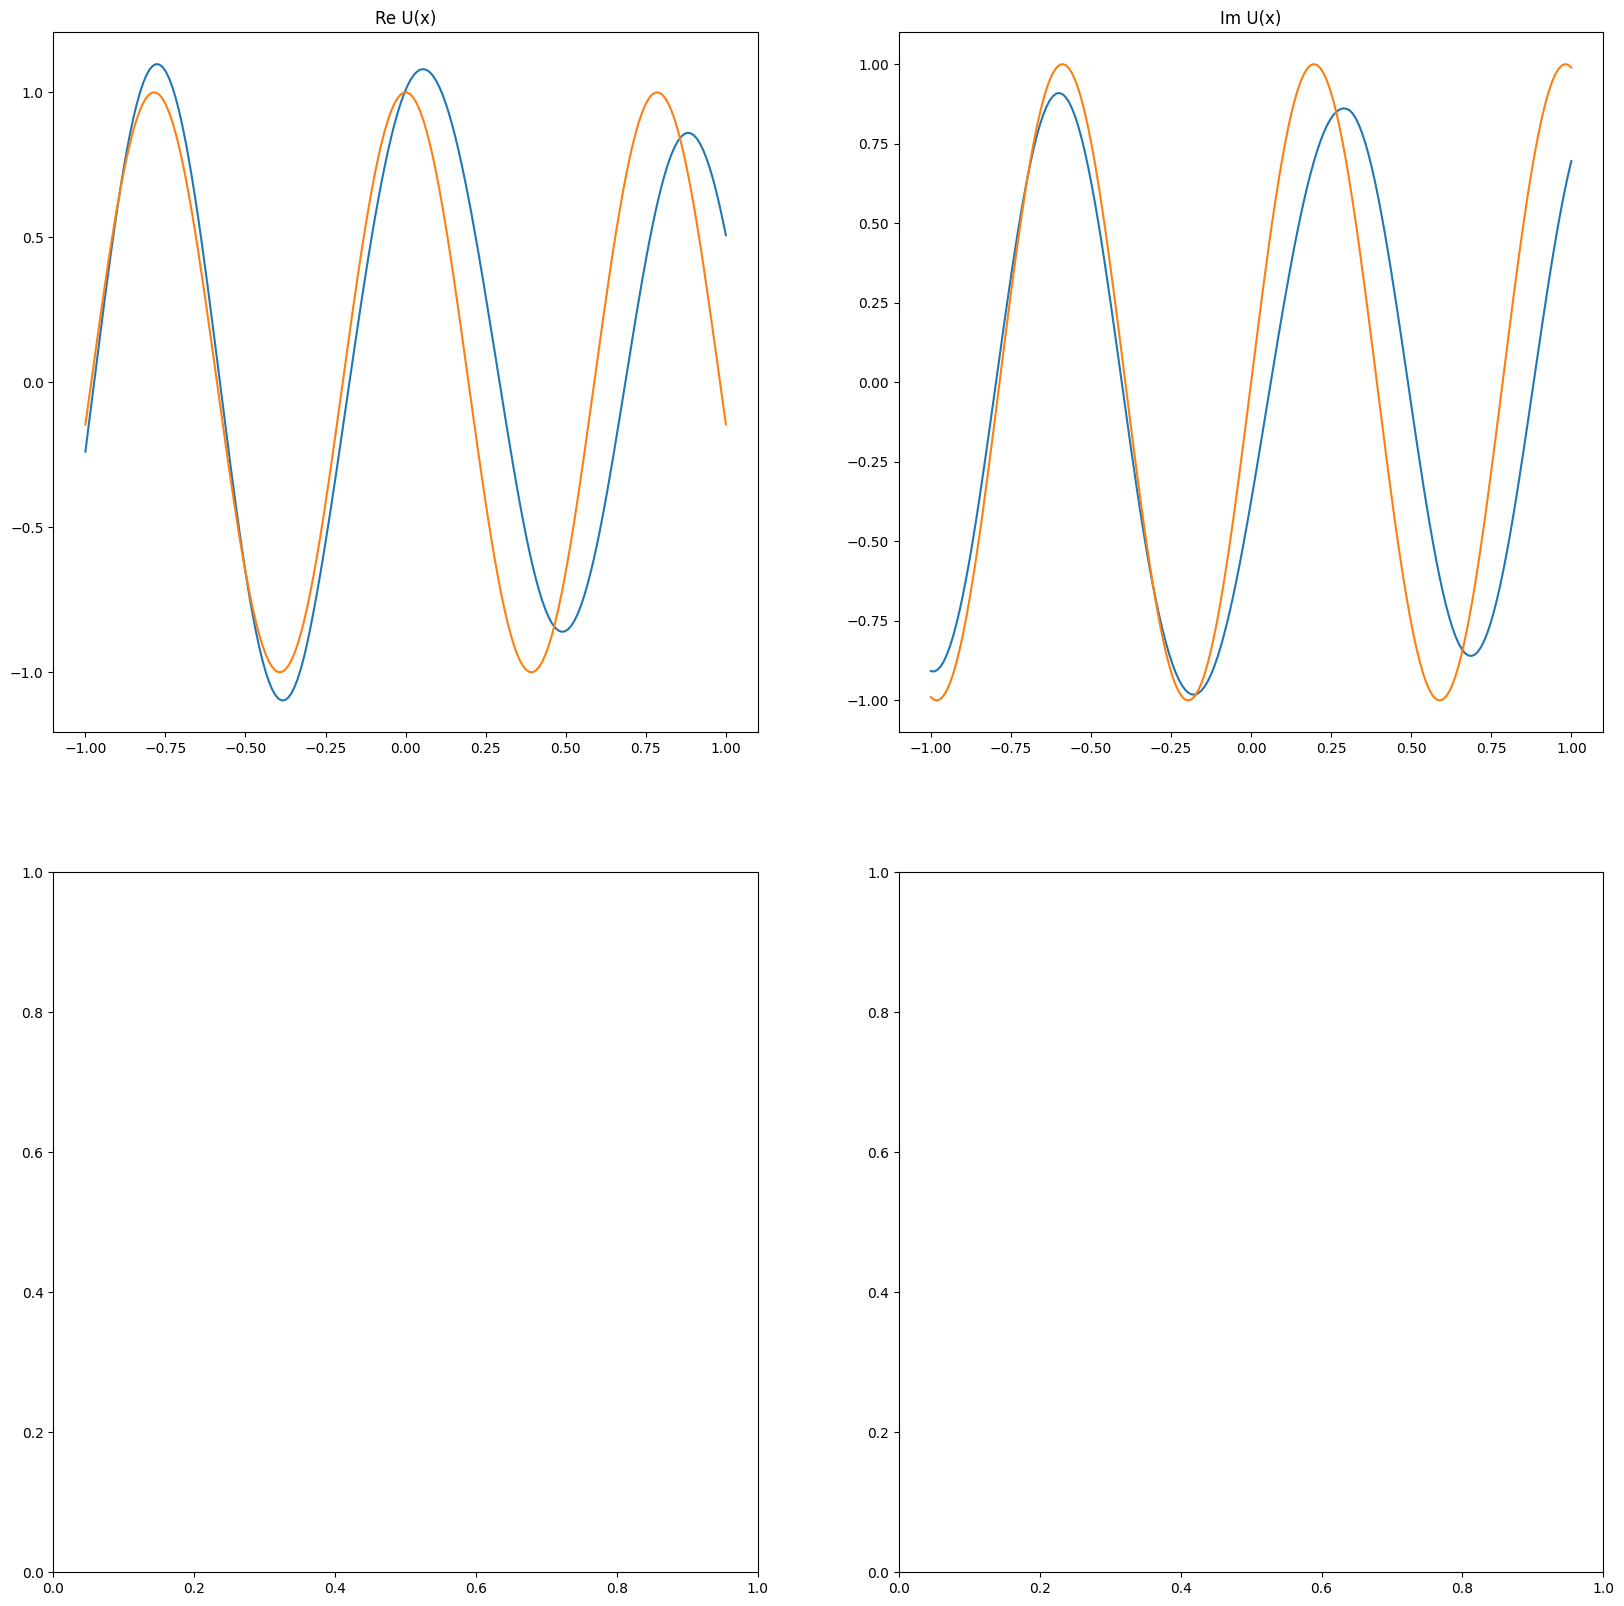

In [142]:
fig, axes = plt.subplots(2, 2, figsize=(20, 20))

axes[0, 0].plot(x, u.real, label='Re u')
axes[0, 0].plot(x, u0.real, label='Re u0')
axes[0, 0].set_title('Re U(x)')

axes[0, 1].plot(x, u.imag, label='Im u')
axes[0, 1].plot(x, u0.imag, label='Im u0')
axes[0, 1].set_title('Im U(x)')

plt.show()